# Бинарная классификация: ирисы и вино

In [1]:
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
# дополнительно для вина
import matplotlib
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                               roc_auc_score, confusion_matrix)

print("numpy", np.__version__)
print("pandas", pd.__version__)
print("matplotlib", matplotlib.__version__)
import sklearn, seaborn
print("sklearn", sklearn.__version__)
print("seaborn", seaborn.__version__)

numpy 2.4.6
pandas 3.1.0
matplotlib 3.11.2
sklearn 1.9.1
seaborn 0.13.2


## 1. Ирисы Фишера: загрузка, объекты/ответы/тип задачи, pairplot

ирисы: загружены по URL
(150, 5)
     длина чашелистика  ширина чашелистика  длина лепестка  ширина лепестка            класс
114                5.8                 2.8             5.1              2.4   Iris-virginica
62                 6.0                 2.2             4.0              1.0  Iris-versicolor
33                 5.5                 4.2             1.4              0.2      Iris-setosa
107                7.3                 2.9             6.3              1.8   Iris-virginica
7                  5.0                 3.4             1.5              0.2      Iris-setosa
Размер выборки составляет l=150 объектов.
Признаки n=4 (вещественные): X in R^(l x n). Ответы: 3 класса -> классификация на M=3.
класс
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50


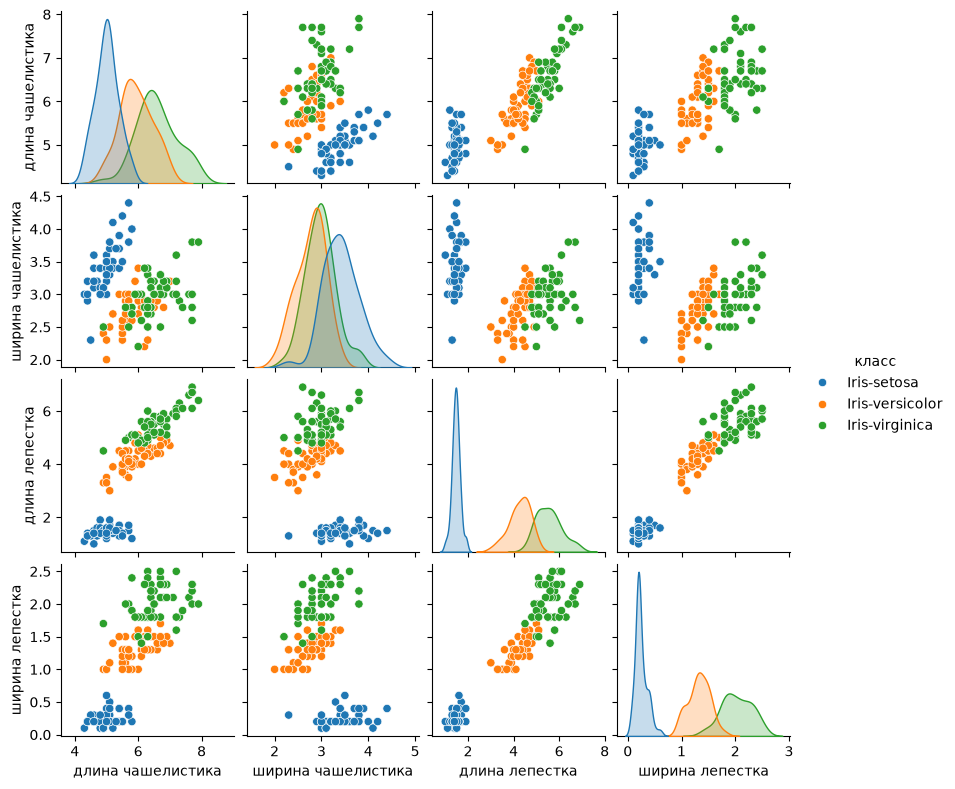

In [2]:
dataset = pd.read_csv('https://raw.githubusercontent.com/andriygav/MachineLearningSeminars/master/sem1/data/iris.csv', 
                      header=None, 
                      names=['длина чашелистика', 'ширина чашелистика', 
                             'длина лепестка', 'ширина лепестка', 'класс'])
dataset.sample(5, random_state=0)
IRIS_URL = ("https://raw.githubusercontent.com/andriygav/"
            "MachineLearningSeminars/master/sem1/data/iris.csv")
COLS = ["длина чашелистика", "ширина чашелистика",
        "длина лепестка", "ширина лепестка", "класс"]
try:
    dataset = pd.read_csv(IRIS_URL, header=None, names=COLS)
    print("ирисы: загружены по URL")
except Exception as e:
    print("ирисы: URL недоступен,", type(e).__name__, "-> ищу локальный iris.csv")
    import glob as _g, os as _os
    _name = "iris.csv"
    _cands = ([_name] if _os.path.exists(_name) else []) + sorted(
        _g.glob("../*/*.csv") + _g.glob("../*/*/*.csv")
        + _g.glob("*/*.csv") + _g.glob("*/*/*.csv"))
    _src = [q for q in _cands if q.endswith(_name)]
    if not _src:
        raise FileNotFoundError("iris.csv не найден: ни URL, ни локальный файл " + repr(_cands))
    print("ирисы: локальный файл:", _src[0])
    dataset = pd.read_csv(_src[0], header=None, names=COLS)
assert dataset.shape == (150, 5), dataset.shape
print(dataset.shape)
print(dataset.sample(5, random_state=0).to_string())
print('Размер выборки составляет l={} объектов.'.format(len(dataset)))
print("Признаки n=4 (вещественные): X in R^(l x n). Ответы: 3 класса -> классификация на M=3.")
print(dataset["класс"].value_counts().to_string())

sns.pairplot(dataset, hue="класс", height=2)
plt.savefig("iris_pairplot.png", dpi=120, bbox_inches="tight")
plt.show()

## 2. Бинаризация Ирисов + LogisticRegression

In [3]:
binary_dataset = dataset.drop(index=dataset.index[dataset['класс'] == 'Iris-setosa'])
binary_dataset['класс'] = binary_dataset['класс'].astype(object)  # адаптер pandas 3.x: str-блок не принимает int; в pandas <3 колонка и была object
binary_dataset.loc[dataset['класс'] == 'Iris-versicolor', dataset.columns == 'класс'] = -1
binary_dataset.loc[dataset['класс'] == 'Iris-virginica', dataset.columns == 'класс'] = 1
print(binary_dataset["класс"].value_counts().to_string())

X = binary_dataset.iloc[:, binary_dataset.columns != "класс"].values
y = binary_dataset.iloc[:, binary_dataset.columns == "класс"].values.reshape(-1)
X = np.array(np.hstack([X, np.ones([len(X), 1])]), dtype=np.float64)
y = np.array(y, dtype=np.int64)
print("X:", X.shape, "y:", y.shape)

model = LogisticRegression(random_state=0, max_iter=2000)
_ = model.fit(X, y)
print("coef_ =", model.coef_)
print("intercept_ =", model.intercept_)
print("train accuracy =", model.score(X, y), "(in-sample — репродукция coef_, не оценка обобщения)")
# Замечание: ручной bias-столбец + fit_intercept=True дублируют сдвиг (intercept_ ~ -14.4, а 5-й coef ~ 0).
# Чистый вариант без дублирования — ниже на вине (fit_intercept по умолчанию, без столбца единиц).

класс
-1    50
1     50
X: (100, 5) y: (100,)
coef_ = [[-3.94857799e-01 -5.12236925e-01  2.93150207e+00  2.41616121e+00
  -1.17463494e-03]]
intercept_ = [-14.4321705]
train accuracy = 0.96 (in-sample — репродукция coef_, не оценка обобщения)


## 3. Индивидуальное задание: winequality-red.csv — «Хорошее» (quality ≥ 7) vs «Некачественное»

вино: файл: winequality-red.csv
(1599, 12)
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  alcohol  quality
0            7.4              0.70         0.00             1.9      0.076                 11.0                  34.0   0.9978  3.51       0.56      9.4        5
1            7.8              0.88         0.00             2.6      0.098                 25.0                  67.0   0.9968  3.20       0.68      9.8        5
2            7.8              0.76         0.04             2.3      0.092                 15.0                  54.0   0.9970  3.26       0.65      9.8        5
3           11.2              0.28         0.56             1.9      0.075                 17.0                  60.0   0.9980  3.16       0.58      9.8        6
4            7.4              0.70         0.00             1.9      0.076                 11.0                  34.0   0.9978  3.51       0.56    

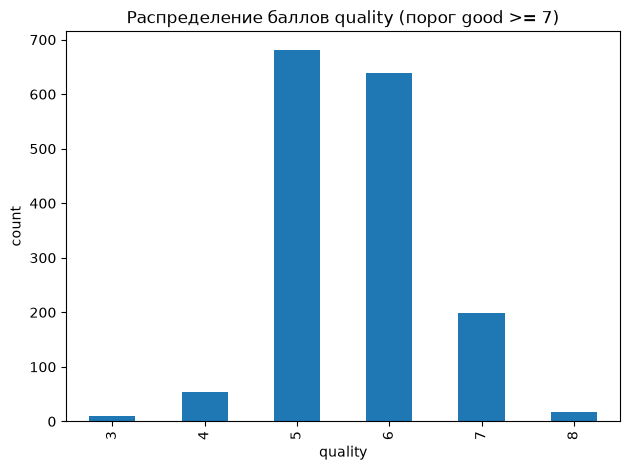

In [4]:
import glob as _g, os as _os
_wname = "winequality-red.csv"
_wc = ([_wname] if _os.path.exists(_wname) else []) + sorted(
    _g.glob("../*/*.csv") + _g.glob("../*/*/*.csv")
    + _g.glob("*/*.csv") + _g.glob("*/*/*.csv"))
_wsrc = [q for q in _wc if q.endswith(_wname)]
if not _wsrc:
    raise FileNotFoundError("winequality-red.csv не найден: кандидаты " + repr(_wc))
print("вино: файл:", _wsrc[0])
wine = pd.read_csv(_wsrc[0])
try:
    _w = pd.read_csv(_wsrc[0], sep=",")
    if _w.shape[1] < 2:
        raise ValueError("single column — пробую sep=';'")
    wine = _w
except Exception:
    try:
        wine = pd.read_csv(_wsrc[0], sep=None, engine="python")
    except Exception:
        wine = pd.read_csv(_wsrc[0], sep=";")
print(wine.shape)
print(wine.head().to_string())
print(wine["quality"].value_counts().sort_index().to_string())
wine["good"] = (wine["quality"] >= 7).astype(int)  # 1 = Хорошее, 0 = Некачественное
print("positive rate:", wine["good"].mean(), "pos:", int(wine['good'].sum()))

plt.figure()
wine["quality"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("quality")
plt.ylabel("count")
plt.title("Распределение баллов quality (порог good >= 7)")
plt.tight_layout()
plt.savefig("wine_quality_hist.png", dpi=120, bbox_inches="tight")
plt.show()

train/test: (1279, 11) (320, 11)
acc=0.8938 prec=0.6957 rec=0.3721 f1=0.4848 auc=0.8804
confusion_matrix:
 [[270   7]
 [ 27  16]]
coef: {'fixed acidity': np.float64(0.2177), 'volatile acidity': np.float64(-0.4257), 'citric acid': np.float64(0.1054), 'residual sugar': np.float64(0.2387), 'chlorides': np.float64(-0.3678), 'free sulfur dioxide': np.float64(0.2773), 'total sulfur dioxide': np.float64(-0.8174), 'density': np.float64(-0.2755), 'pH': np.float64(-0.1517), 'sulphates': np.float64(0.6111), 'alcohol': np.float64(0.8944)}
intercept: -2.8064
Гиперплоскость: (+0.2177*fixed acidity + -0.4257*volatile acidity + +0.1054*citric acid + +0.2387*residual sugar + -0.3678*chlorides + +0.2773*free sulfur dioxide + -0.8174*total sulfur dioxide + -0.2755*density + -0.1517*pH + +0.6111*sulphates + +0.8944*alcohol) + (-2.8064) = 0; good=1 если > 0


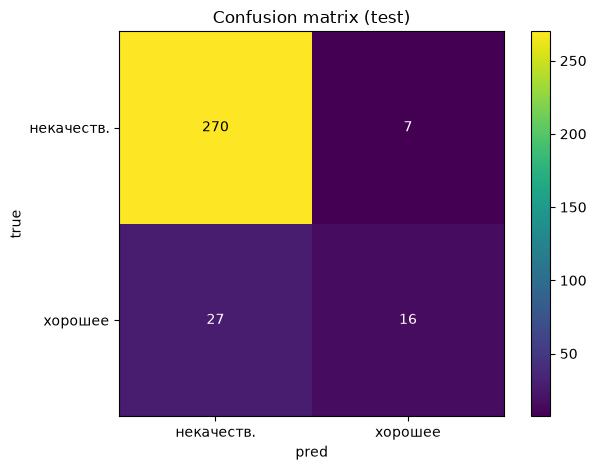

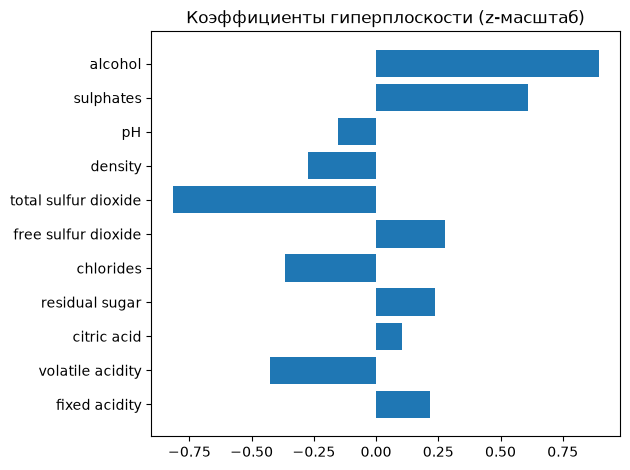

In [5]:
FEATS = [c for c in wine.columns if c not in ("quality", "good")]
Xw = wine[FEATS].to_numpy()
yw = wine["good"].to_numpy()
Xtr, Xte, ytr, yte = train_test_split(Xw, yw, test_size=0.2, random_state=42, stratify=yw)
scaler = StandardScaler().fit(Xtr)  # стандартизация по train (подготовка наборов данных)
Xtrs, Xtes = scaler.transform(Xtr), scaler.transform(Xte)
print("train/test:", Xtrs.shape, Xtes.shape)

clf = LogisticRegression(random_state=0, max_iter=5000)
clf.fit(Xtrs, ytr)
p = clf.predict(Xtes)
pr = clf.predict_proba(Xtes)[:, 1]
print(f"acc={accuracy_score(yte, p):.4f} prec={precision_score(yte, p):.4f} "
      f"rec={recall_score(yte, p):.4f} f1={f1_score(yte, p):.4f} auc={roc_auc_score(yte, pr):.4f}")
print("confusion_matrix:\n", confusion_matrix(yte, p))
print("coef:", dict(zip(FEATS, np.round(clf.coef_[0], 4))))
print("intercept:", round(float(clf.intercept_[0]), 4))
# Уравнение гиперповерхности (в стандартизованном пространстве z): theta^T z + b = 0
terms = " + ".join(f"{c:+.4f}*{n}" for c, n in zip(clf.coef_[0], FEATS))
print(f"Гиперплоскость: ({terms}) + ({float(clf.intercept_[0]):+.4f}) = 0; good=1 если > 0")

cm = confusion_matrix(yte, p)
plt.figure()
plt.imshow(cm)
plt.xticks([0, 1], ["некачеств.", "хорошее"])
plt.yticks([0, 1], ["некачеств.", "хорошее"])
for _i in range(2):
    for _j in range(2):
        plt.text(_j, _i, cm[_i, _j], ha="center", va="center",
                 color="white" if cm[_i, _j] < cm.max() / 2 else "black")
plt.title("Confusion matrix (test)")
plt.xlabel("pred"); plt.ylabel("true")
plt.colorbar()
plt.tight_layout()
plt.savefig("wine_confusion.png", dpi=120, bbox_inches="tight")
plt.show()

plt.figure()
plt.barh(FEATS, clf.coef_[0])
plt.title("Коэффициенты гиперплоскости (z-масштаб)")
plt.tight_layout()
plt.savefig("wine_coef.png", dpi=120, bbox_inches="tight")
plt.show()

## 3.1. Решение проблемы дисбаланса классов (good = 217/1599 = 13.6%)

Дефолтный порог 0.5 при 86% отрицательного класса душит minority-класс: recall 0.37 при честном ранжировании (AUC 0.88). Модель «почти всегда говорит: не качественное». Лечим порогом, проверяем альтернативу через веса классов.



пороги по фолдам: [np.float64(0.33), np.float64(0.24), np.float64(0.22), np.float64(0.17), np.float64(0.34)] -> выбранный порог = 0.24
baseline     thr=0.5       -> {'acc': 0.8938, 'prec': 0.6957, 'rec': 0.3721, 'f1': 0.4848, 'auc': 0.8804}
balanced     thr=0.5       -> {'acc': 0.8125, 'prec': 0.4, 'rec': 0.7907, 'f1': 0.5312, 'auc': 0.8824}
baseline + порог 0.24 (CV) -> {'acc': 0.8688, 'prec': 0.5091, 'rec': 0.6512, 'f1': 0.5714, 'auc': 0.8804}


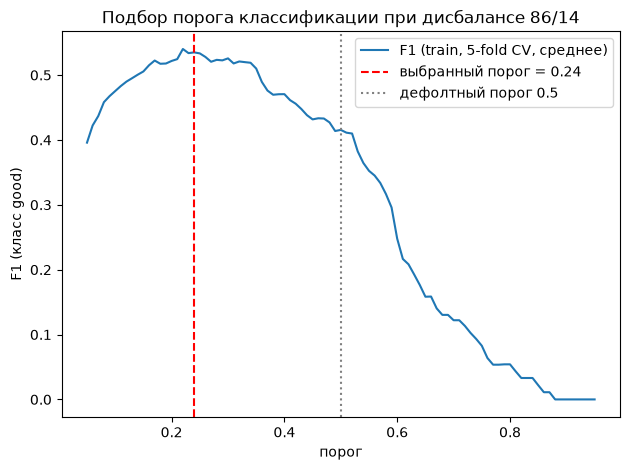

confusion_matrix (baseline + порог):
 [[250  27]
 [ 15  28]]


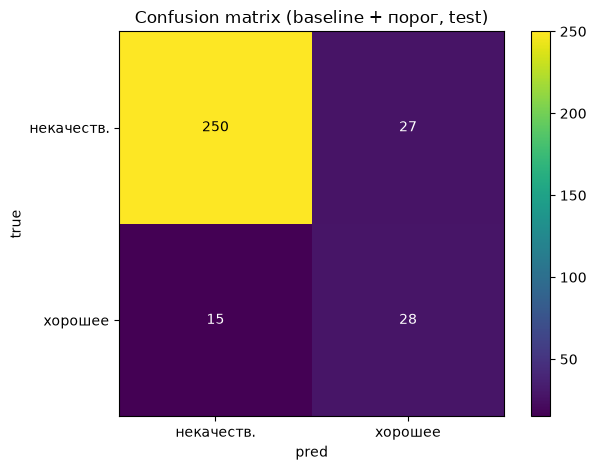

In [6]:
# A. class_weight="balanced": вес потерь ~ 1/частость класса (эквивалент оверсэмплинга без копирования строк)
clf_bal = LogisticRegression(random_state=0, max_iter=5000, class_weight="balanced")
clf_bal.fit(Xtrs, ytr)

# B. подберём порог по F1 через 5-fold CV на TRAIN (к test не подглядываем); устойчивый выбор — медиана по фолдам
grid = np.linspace(0.05, 0.95, 91)
cv = StratifiedKFold(5, shuffle=True, random_state=42)
fold_thr = []
for tr_i, va_i in cv.split(Xtrs, ytr):
    m = LogisticRegression(random_state=0, max_iter=5000).fit(Xtrs[tr_i], ytr[tr_i])
    pv = m.predict_proba(Xtrs[va_i])[:, 1]
    fold_thr.append(grid[int(np.argmax([f1_score(ytr[va_i], (pv >= t).astype(int), zero_division=0) for t in grid]))])
thr = float(np.median(fold_thr))
print(f"пороги по фолдам: {[round(t, 2) for t in fold_thr]} -> выбранный порог = {thr:.2f}")

def metrics(tag, probs, threshold):
    p = (probs >= threshold).astype(int)
    return (tag, {"acc": round(accuracy_score(yte, p), 4), "prec": round(precision_score(yte, p, zero_division=0), 4),
                  "rec": round(recall_score(yte, p), 4), "f1": round(f1_score(yte, p), 4),
                  "auc": round(roc_auc_score(yte, probs), 4)})

pr_bal = clf_bal.predict_proba(Xtes)[:, 1]
for tag, m in [metrics("baseline     thr=0.5      ", pr, 0.5),
               metrics("balanced     thr=0.5      ", pr_bal, 0.5),
               metrics(f"baseline + порог {thr:.2f} (CV)", pr, thr)]:
    print(tag, "->", m)
# AUC не меняется порогом и почти не меняется весами: ранжирование одно и то же, лечится именно решение (порог).

# C. кривая F1(порог): средняя по 5 фолдам CV на train + выбранный и дефолтный пороги
th_all = np.linspace(0.05, 0.95, 91)
f1_folds = []
for tr_i, va_i in cv.split(Xtrs, ytr):
    m = LogisticRegression(random_state=0, max_iter=5000).fit(Xtrs[tr_i], ytr[tr_i])
    pv = m.predict_proba(Xtrs[va_i])[:, 1]
    f1_folds.append([f1_score(ytr[va_i], (pv >= t).astype(int), zero_division=0) for t in th_all])
f1_mean = np.mean(f1_folds, axis=0)

plt.figure()
plt.plot(th_all, f1_mean, label="F1 (train, 5-fold CV, среднее)")
plt.axvline(thr, color="red", ls="--", label=f"выбранный порог = {thr:.2f}")
plt.axvline(0.5, color="gray", ls=":", label="дефолтный порог 0.5")
plt.xlabel("порог")
plt.ylabel("F1 (класс good)")
plt.title("Подбор порога классификации при дисбалансе 86/14")
plt.legend()
plt.tight_layout()
plt.savefig("wine_threshold.png", dpi=120, bbox_inches="tight")
plt.show()

print("confusion_matrix (baseline + порог):\n", confusion_matrix(yte, (pr >= thr).astype(int)))
cm_thr = confusion_matrix(yte, (pr >= thr).astype(int))
plt.figure()
plt.imshow(cm_thr)
plt.xticks([0, 1], ["некачеств.", "хорошее"])
plt.yticks([0, 1], ["некачеств.", "хорошее"])
for _i in range(2):
    for _j in range(2):
        plt.text(_j, _i, cm_thr[_i, _j], ha="center", va="center",
                 color="white" if cm_thr[_i, _j] < cm_thr.max() / 2 else "black")
plt.title("Confusion matrix (baseline + порог, test)")
plt.xlabel("pred"); plt.ylabel("true")
plt.colorbar()
plt.tight_layout()
plt.savefig("wine_confusion_thr.png", dpi=120, bbox_inches="tight")
plt.show()


## 3.2. Чистка датасета: дубликаты строк

Порог из п. 3.1 лечит решение модели, но не данные. В самом датасете дефект (посчитан в ячейке живьём): дубликаты строк (~15% — разъезжаются по train/test, это утечка). Чиним данные: `drop_duplicates()` до сплита, затем тот же пайплайн (стратифицированный сплит 80/20, rs=42, стандартизация по train, LogReg, порог по F1 через CV).


строк: 1599 NaN: 0 дубликатов: 240
после дедупа: 1359 строк, positive rate: 0.1354


пороги по фолдам: [np.float64(0.29), np.float64(0.23), np.float64(0.33), np.float64(0.32), np.float64(0.14)] -> порог = 0.29
ЧИСТЫЕ ДАННЫЕ + порог 0.29: acc=0.8640 prec=0.5000 rec=0.6216 f1=0.5542 auc=0.8860
confusion_matrix (чистые данные + порог):
 [[212  23]
 [ 14  23]]


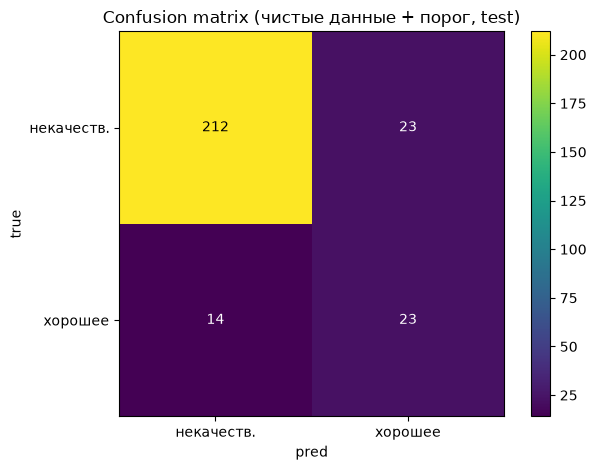

In [7]:
# Дефекты исходного датасета (считаем живьём на wine из п. 3)

print("строк:", len(wine), "NaN:", int(wine.isna().sum().sum()),

      "дубликатов:", int(wine.duplicated().sum()))

# Чистка: дедуп до сплита (строка либо в train, либо в test — утечки нет)
clean = wine.drop_duplicates().reset_index(drop=True).copy()
print("после дедупа:", len(clean), "строк, positive rate:",
      round(float(clean["good"].mean()), 4))

# Тот же пайплайн, что в п. 3: стратифицированный сплит, стандартизация, LogReg

Xc, yc = clean[FEATS].to_numpy(), clean["good"].to_numpy()

Xtrc, Xtec, ytrc, ytec = train_test_split(

    Xc, yc, test_size=0.2, random_state=42, stratify=yc)

scaler_c = StandardScaler().fit(Xtrc)

Xtrcs, Xtecs = scaler_c.transform(Xtrc), scaler_c.transform(Xtec)

clf_c = LogisticRegression(random_state=0, max_iter=5000).fit(Xtrcs, ytrc)

pr_c = clf_c.predict_proba(Xtecs)[:, 1]



# Порог по F1 через 5-fold CV на train (как в п. 3.1, в test не подглядываем)

fold_thr_c = []

for tr_i, va_i in cv.split(Xtrcs, ytrc):

    m = LogisticRegression(random_state=0, max_iter=5000).fit(

        Xtrcs[tr_i], ytrc[tr_i])

    pv = m.predict_proba(Xtrcs[va_i])[:, 1]

    fold_thr_c.append(grid[int(np.argmax(

        [f1_score(ytrc[va_i], (pv >= t).astype(int), zero_division=0)

         for t in grid]))])

thr_c = float(np.median(fold_thr_c))

print(f"пороги по фолдам: {[round(t, 2) for t in fold_thr_c]} "

      f"-> порог = {thr_c:.2f}")



pc = (pr_c >= thr_c).astype(int)

print(f"ЧИСТЫЕ ДАННЫЕ + порог {thr_c:.2f}: "

      f"acc={accuracy_score(ytec, pc):.4f} "

      f"prec={precision_score(ytec, pc, zero_division=0):.4f} "

      f"rec={recall_score(ytec, pc):.4f} f1={f1_score(ytec, pc):.4f} "

      f"auc={roc_auc_score(ytec, pr_c):.4f}")

print("confusion_matrix (чистые данные + порог):\n",

      confusion_matrix(ytec, pc))



cm_c = confusion_matrix(ytec, pc)
plt.figure()
plt.imshow(cm_c)
plt.xticks([0, 1], ["некачеств.", "хорошее"])
plt.yticks([0, 1], ["некачеств.", "хорошее"])
for _i in range(2):
    for _j in range(2):
        plt.text(_j, _i, cm_c[_i, _j], ha="center", va="center",
                 color="white" if cm_c[_i, _j] < cm_c.max() / 2 else "black")
plt.title("Confusion matrix (чистые данные + порог, test)")
plt.xlabel("pred"); plt.ylabel("true")
plt.colorbar()
plt.tight_layout()
plt.savefig("wine_confusion_clean.png", dpi=120, bbox_inches="tight")
plt.show()
